# Task 1 — Data Collection
### QFI Internship · Market Risk Project · Phase 1
**Prepared by:** Arham Shah

---

**Objective.** Build a reliable, documented price dataset for a 10-stock US equity portfolio and its S&P 500 benchmark, which every later phase (cleaning, construction, VaR, backtesting) runs on.

**What this notebook delivers**
- Live download of daily **adjusted close** prices and **volumes** (with retries + offline cache)
- An automated **data-quality scorecard** per ticker (coverage, gaps, stale runs, jumps, liquidity)
- Visual checks: rebased performance, small multiples, calendar-year return heatmap
- Saved raw files + a JSON **data manifest** for reproducibility

> **Pipeline:** **Task 1 (Collection)** → Task 2 (Cleaning) → Task 3 (Construction) → VaR / Backtesting

> **How to run:** open in Google Colab → *Runtime → Run all*. The notebook downloads anything it needs, so it also works if run on its own.

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings('ignore')

try:
    import yfinance as yf
except ImportError:            # Colab usually has it; install if missing
    %pip install -q yfinance
    import yfinance as yf

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

plt.rcParams.update({
    'figure.figsize': (12, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


## 1. Universe, benchmark and window
All settings live in one cell so the whole pipeline can be re-pointed (new tickers, dates) by editing a single place. Each stock is tagged with its sector so we can check diversification.

In [2]:
# ---- Project configuration (single source of truth) ----------------------
UNIVERSE = {                     # ticker : GICS-style sector
    'AAPL' : 'Information Technology',
    'MSFT' : 'Information Technology',
    'NVDA' : 'Information Technology',
    'GOOGL': 'Communication Services',
    'META' : 'Communication Services',
    'AMZN' : 'Consumer Discretionary',
    'TSLA' : 'Consumer Discretionary',
    'JPM'  : 'Financials',
    'XOM'  : 'Energy',
    'UNH'  : 'Health Care',
}
TICKERS    = list(UNIVERSE)
BENCHMARK  = '^GSPC'             # S&P 500
START_DATE = '2020-07-24'
END_DATE   = '2026-07-25'        # yfinance end date is exclusive
TRADING_DAYS = 252

RAW_PRICE_FILE  = 'Raw_Portfolio_Price.csv'
RAW_VOLUME_FILE = 'Raw_Portfolio_Volume.csv'
BENCH_FILE      = 'Benchmark_prices.csv'

print(f'{len(TICKERS)} stocks across {len(set(UNIVERSE.values()))} sectors | '
      f'benchmark {BENCHMARK} | {START_DATE} -> {END_DATE}')

10 stocks across 6 sectors | benchmark ^GSPC | 2020-07-24 -> 2026-07-25


In [3]:
sector_table = (pd.Series(UNIVERSE, name='Sector').rename_axis('Ticker').reset_index()
                .groupby('Sector')['Ticker'].agg(['count', ', '.join])
                .rename(columns={'count': 'N stocks', 'join': 'Tickers'})
                .sort_values('N stocks', ascending=False))
sector_table

,N stocks,Tickers
Sector,,
Information Technology,3,"AAPL, MSFT, NVDA"
Communication Services,2,"GOOGL, META"
Consumer Discretionary,2,"AMZN, TSLA"
Energy,1,XOM
Financials,1,JPM
Health Care,1,UNH


## 2. Download the data
We pull **Adjusted Close** (corrects for splits and dividends, which matters for return-based risk) and **Volume** (used for the liquidity check). If the download fails, for example with no internet, the notebook falls back to previously saved CSVs.

Set `FORCE_REFRESH = True` to always re-download.

In [4]:
# ---- Robust Yahoo Finance downloader (retries + clear errors) ------------
def download_yahoo(symbols, start, end, retries=3, pause=2):
    """Return (adj_close, volume) DataFrames for `symbols`."""
    symbols = [symbols] if isinstance(symbols, str) else list(symbols)
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            raw = yf.download(symbols, start=start, end=end, auto_adjust=False,
                              progress=False, threads=True, group_by='column')
            adj, vol = raw['Adj Close'], raw['Volume']
            if isinstance(adj, pd.Series):
                adj, vol = adj.to_frame(symbols[0]), vol.to_frame(symbols[0])
            adj, vol = adj[symbols].dropna(how='all'), vol[symbols].reindex(adj.dropna(how='all').index)
            if not adj.empty:
                return adj, vol
            last_err = 'empty response'
        except Exception as e:
            last_err = e
        print(f'  attempt {attempt}/{retries} failed ({last_err}); retrying...')
        time.sleep(pause * attempt)
    raise RuntimeError(f'Yahoo download failed for {symbols}: {last_err}')

In [5]:
FORCE_REFRESH = True

def load_cached():
    p = pd.read_csv(RAW_PRICE_FILE, index_col=0, parse_dates=True)
    v = pd.read_csv(RAW_VOLUME_FILE, index_col=0, parse_dates=True) if os.path.exists(RAW_VOLUME_FILE) else None
    b = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True).iloc[:, 0]
    return p, v, b

cache_ok = all(os.path.exists(f) for f in [RAW_PRICE_FILE, BENCH_FILE])
try:
    if cache_ok and not FORCE_REFRESH:
        raise RuntimeError('using cache by choice')
    print('Downloading portfolio constituents...')
    prices, volumes = download_yahoo(TICKERS, START_DATE, END_DATE)
    print('Downloading benchmark...')
    bench_df, _ = download_yahoo(BENCHMARK, START_DATE, END_DATE)
    benchmark = bench_df.iloc[:, 0]
    DATA_SOURCE = 'Yahoo Finance (live download via yfinance)'
except Exception as e:
    if not cache_ok:
        raise RuntimeError('No internet and no cached CSVs - upload Raw_Portfolio_Price.csv '
                           'and Benchmark_prices.csv to the Colab session and re-run.') from e
    print(f'Live download skipped ({e}); loading cached CSVs.')
    prices, volumes, benchmark = load_cached()
    DATA_SOURCE = 'Cached CSV files'

prices.index.name = benchmark.index.name = 'Date'
benchmark.name = 'S&P 500'
print(f'\nSource    : {DATA_SOURCE}')
print(f'Prices    : {prices.shape[0]} days x {prices.shape[1]} stocks')
print(f'Benchmark : {len(benchmark)} days')
prices.tail()


Source    : Yahoo Finance (live download via yfinance)
Prices    : 1507 days x 10 stocks
Benchmark : 1507 days


Ticker,AAPL,MSFT,NVDA,GOOGL,META,AMZN,TSLA,JPM,XOM,UNH
Date,,,,,,,,,,
2026-07-20,326.3086,401.5341,203.0528,351.7639,645.3407,249.9900,369.5700,337.1878,147.4055,418.9702
2026-07-21,327.4576,397.0026,207.0583,346.9270,643.3023,247.5500,378.9300,343.5162,150.7340,433.6796
2026-07-22,325.6092,389.6066,211.8230,341.8702,626.6754,244.8500,374.0100,346.4814,153.4563,428.6704
2026-07-23,321.3828,380.8630,208.5267,317.4859,605.6220,233.6600,319.6900,348.1630,155.8806,420.9679
2026-07-24,332.7330,380.9828,206.6088,319.5346,594.7206,232.1100,313.0300,351.4566,155.9303,418.1651


## 3. Data-quality scorecard
Instead of eyeballing a few print statements, every ticker is scored on the checks a risk team would actually run before trusting a dataset:

| Check | Why it matters for market risk |
|---|---|
| Coverage vs. benchmark calendar | Missing days create fake zero-returns or misaligned P&L |
| Longest stale run | A frozen price feed underestimates volatility and VaR |
| Zero-volume days | Suggests no real trading, so the price is not reliable |
| Non-positive prices | Impossible for equities; breaks log returns |
| Largest one-day move | Very large jumps may be bad ticks or unadjusted splits |
| Avg. dollar volume | Liquidity, i.e. whether positions could be exited at the quoted price |

In [6]:
# Align to the benchmark trading calendar (the 'official' set of market days)
calendar = benchmark.index
extra_days = prices.index.difference(calendar)          # days stocks have but index doesn't
prices  = prices.reindex(calendar)
volumes = volumes.reindex(calendar) if volumes is not None else None
print(f'Trading days in window : {len(calendar)}  ({calendar.min().date()} -> {calendar.max().date()})')
print(f'Duplicate dates        : {int(calendar.duplicated().sum())}')
print(f'Stock-only dates dropped: {len(extra_days)}')

def longest_stale_run(s):
    """Longest run of consecutive identical closes (1 = price changed every day)."""
    s = s.dropna()
    same = s.eq(s.shift())
    return int(same.groupby((~same).cumsum()).sum().max()) + 1 if len(s) else 0

rets_simple = prices.pct_change(fill_method=None)
rows = []
for t in TICKERS:
    p = prices[t]
    big = rets_simple[t].abs().idxmax()
    row = {
        'Sector'        : UNIVERSE[t],
        'First date'    : p.first_valid_index().date(),
        'Last date'     : p.last_valid_index().date(),
        'Coverage %'    : 100 * p.notna().mean(),
        'Missing days'  : int(p.isna().sum()),
        'Max stale run' : longest_stale_run(p),
        'Non-positive'  : int((p <= 0).sum()),
        'Max |1d move| %': 100 * rets_simple[t].abs().max(),
        'Max move date' : big.date(),
        'Min price'     : p.min(),
        'Max price'     : p.max(),
    }
    if volumes is not None:
        row['Zero-vol days'] = int((volumes[t] == 0).sum())
        row['Avg $ vol (bn)'] = (prices[t] * volumes[t]).mean() / 1e9
    rows.append(row)
quality = pd.DataFrame(rows, index=pd.Index(TICKERS, name='Ticker'))

# Flag anything a reviewer should look at
def status(r):
    issues = []
    if r['Coverage %'] < 99.5:   issues.append('gaps')
    if r['Max stale run'] >= 5:  issues.append('stale')   # a frozen week
    if r['Non-positive'] > 0:    issues.append('bad price')
    if r['Max |1d move| %'] > 40: issues.append('jump')
    if r.get('Zero-vol days', 0) > 0: issues.append('zero volume')
    return 'OK' if not issues else 'REVIEW: ' + ', '.join(issues)
quality['Status'] = quality.apply(status, axis=1)
quality

Trading days in window : 1507  (2020-07-24 -> 2026-07-24)
Duplicate dates        : 0
Stock-only dates dropped: 0


,Sector,First date,Last date,Coverage %,Missing days,Max stale run,Non-positive,Max |1d move| %,Max move date,Min price,Max price,Zero-vol days,Avg $ vol (bn),Status
Ticker,,,,,,,,,,,,,,
AAPL,Information Technology,2020-07-24,2026-07-24,100.0000,0,2,0,15.3289,2025-04-09,89.5951,333.4524,0,12.4653,OK
MSFT,Information Technology,2020-07-24,2026-07-24,100.0000,0,2,0,10.1337,2025-04-09,190.5711,537.6464,0,8.8475,OK
NVDA,Information Technology,2020-07-24,2026-07-24,100.0000,0,2,0,24.3697,2023-05-25,10.1361,235.2024,0,20.8187,OK
GOOGL,Communication Services,2020-07-24,2026-07-24,100.0000,0,2,0,10.2244,2024-04-26,69.8052,402.1212,0,5.1260,OK
META,Communication Services,2020-07-24,2026-07-24,100.0000,0,2,0,26.3901,2022-02-03,88.0665,786.7983,0,7.2911,OK
AMZN,Consumer Discretionary,2020-07-24,2026-07-24,100.0000,0,3,0,14.0494,2022-04-29,81.8200,274.9900,0,9.6476,OK
TSLA,Consumer Discretionary,2020-07-24,2026-07-24,100.0000,0,2,0,22.6900,2025-04-09,91.6260,489.8800,0,25.4464,OK
JPM,Financials,2020-07-24,2026-07-24,100.0000,0,2,0,13.5392,2020-11-09,79.1090,351.4566,0,1.8925,OK
XOM,Energy,2020-07-24,2026-07-24,100.0000,0,2,0,12.6602,2020-11-09,24.6991,169.2183,0,1.7016,OK


In [7]:
n_ok = (quality['Status'] == 'OK').sum()
print(f'{n_ok}/{len(quality)} tickers pass every check.')
for t, r in quality[quality['Status'] != 'OK'].iterrows():
    print(f'  {t}: {r["Status"]} (largest move {r["Max |1d move| %"]:.1f}% on {r["Max move date"]})')
print(f'\nBenchmark missing days: {int(benchmark.isna().sum())}')
print('\nNote: big single-day moves on earnings dates (e.g. META Feb-2022) are real market events, '
      'not data errors - they are exactly the tail events VaR must capture.')

10/10 tickers pass every check.

Benchmark missing days: 0

Note: big single-day moves on earnings dates (e.g. META Feb-2022) are real market events, not data errors - they are exactly the tail events VaR must capture.


## 4. Visual checks
### 4a. Rebased performance (start = 100, log scale)
Rebasing puts every stock on the same footing. A log scale makes equal percentage moves look the same size, so NVDA's large rally doesn't flatten everything else.

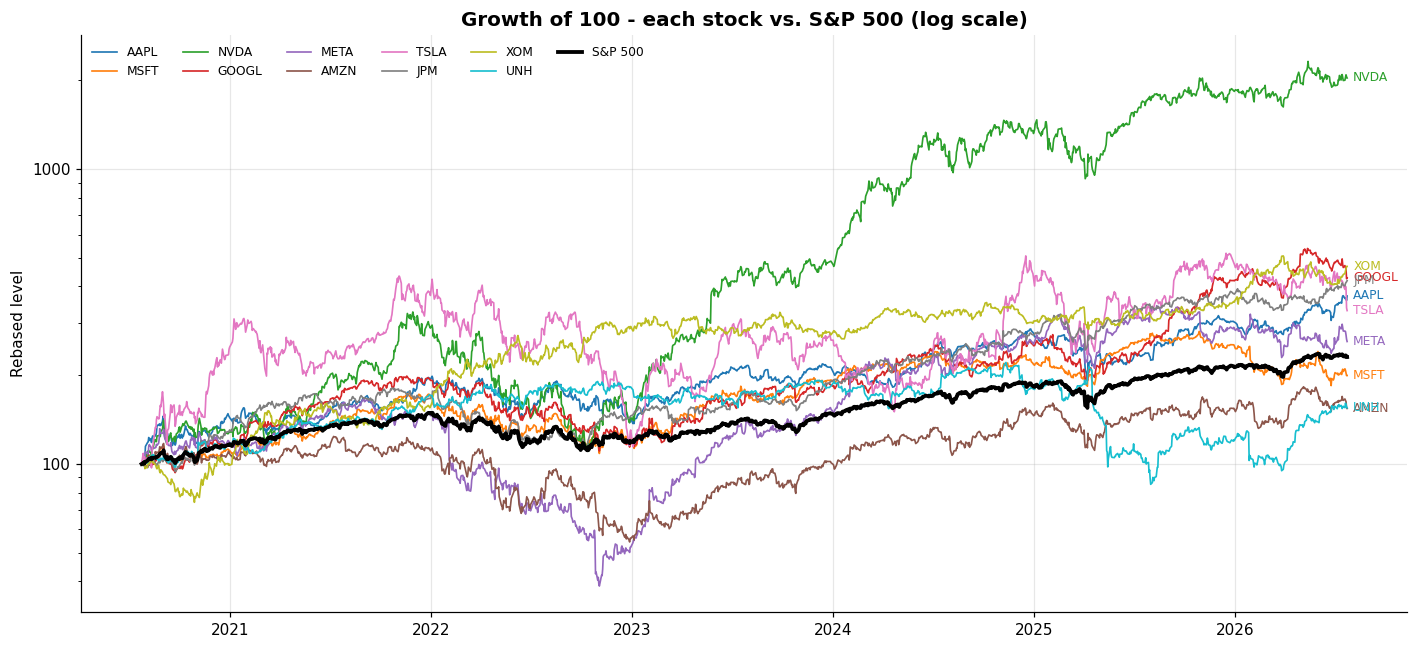

In [8]:
rebased = prices.div(prices.bfill().iloc[0]).mul(100)
bench_rebased = benchmark / benchmark.iloc[0] * 100

fig, ax = plt.subplots(figsize=(13, 6))
cmap = plt.get_cmap('tab10')
for i, t in enumerate(TICKERS):
    ax.plot(rebased.index, rebased[t], lw=1.1, color=cmap(i), label=t)
    ax.annotate(t, (rebased.index[-1], rebased[t].iloc[-1]), xytext=(4, 0),
                textcoords='offset points', fontsize=8, color=cmap(i), va='center')
ax.plot(bench_rebased.index, bench_rebased, color='black', lw=2.5, label='S&P 500')
ax.set_yscale('log'); ax.yaxis.set_major_formatter(mtick.ScalarFormatter())
ax.set_title('Growth of 100 - each stock vs. S&P 500 (log scale)')
ax.set_ylabel('Rebased level'); ax.legend(ncol=6, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

### 4b. Small multiples: each stock against the benchmark
Flat segments, gaps or sudden cliffs that are not reflected in the market would show up here.

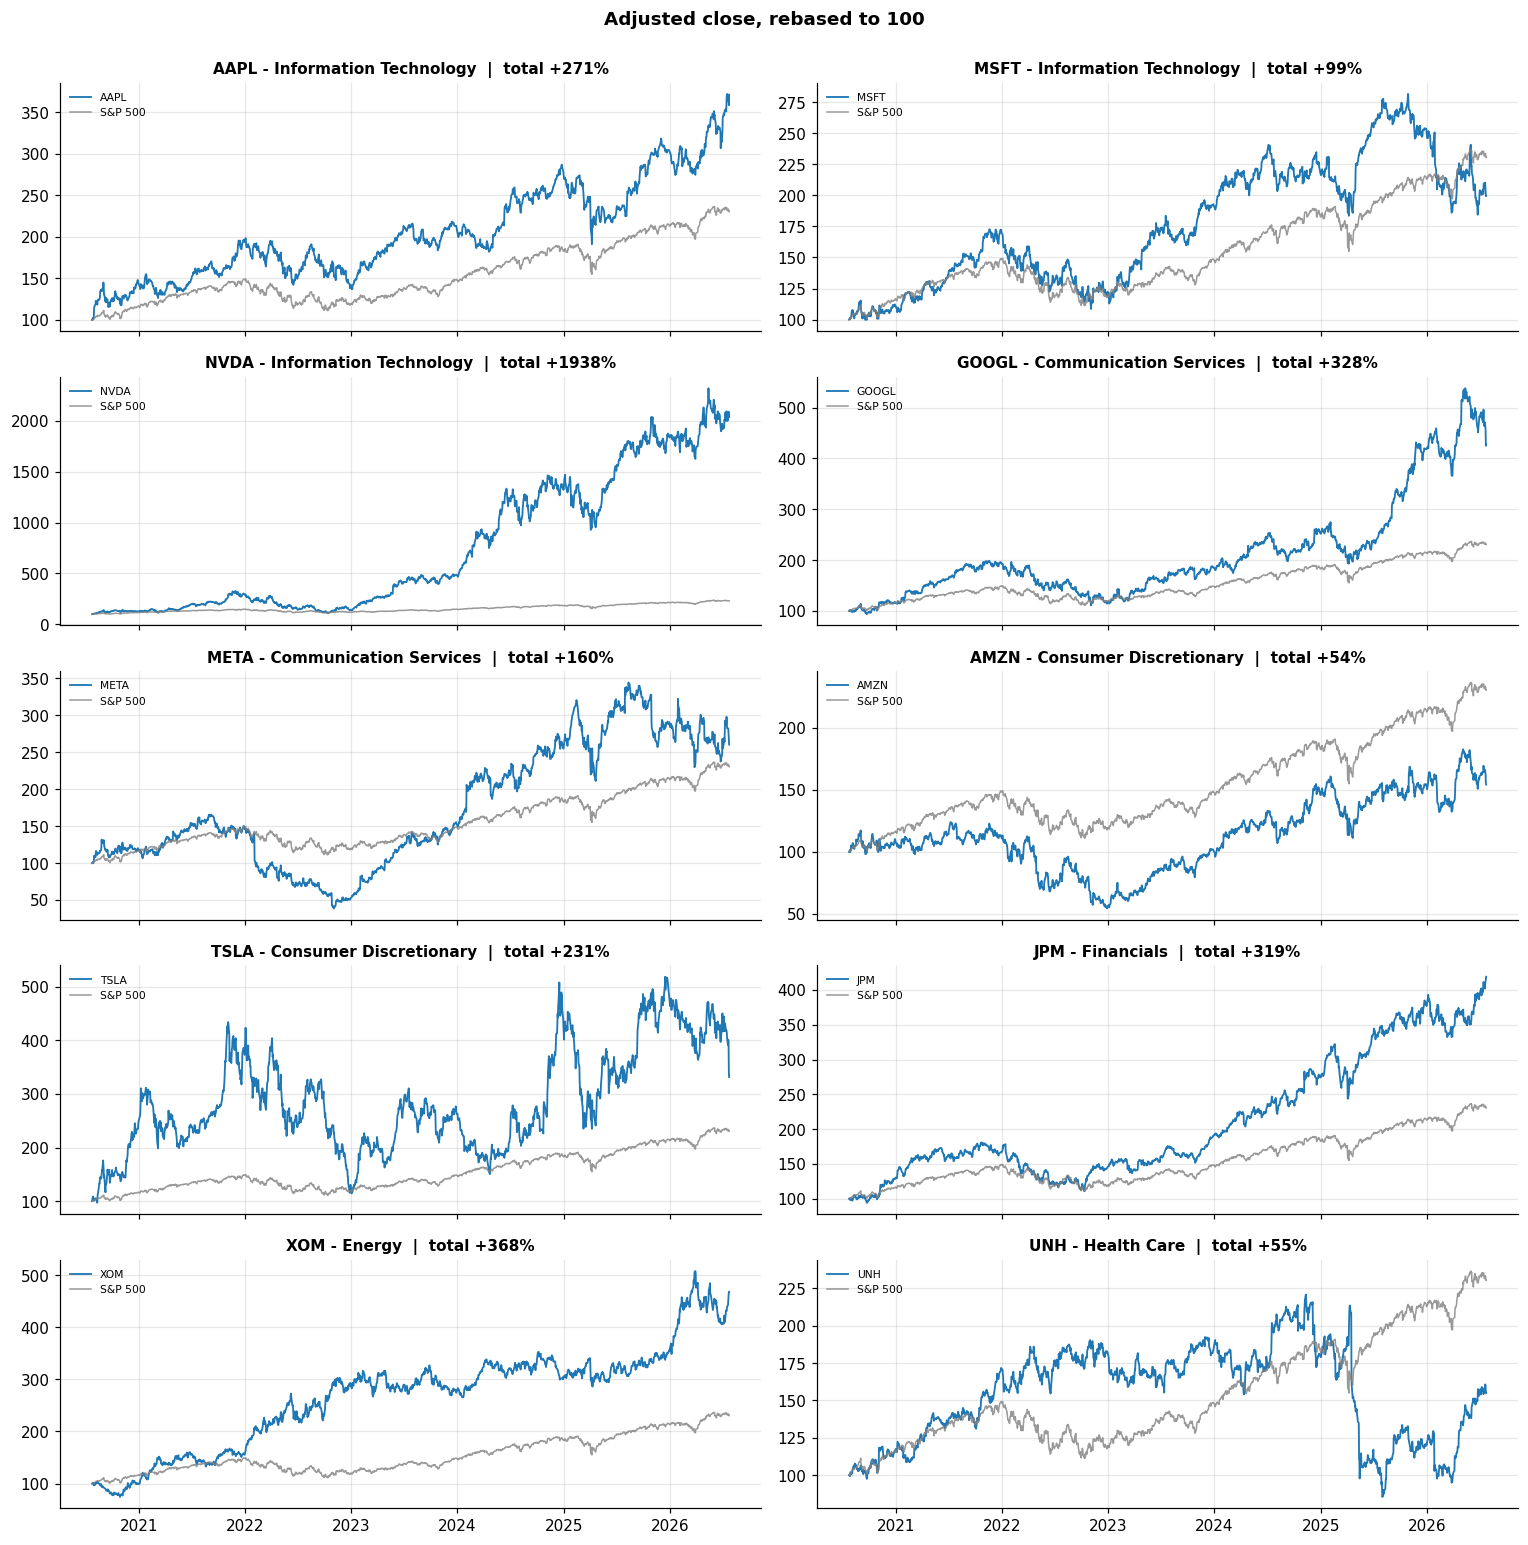

In [9]:
fig, axes = plt.subplots(5, 2, figsize=(14, 14), sharex=True)
for ax, t in zip(axes.flat, TICKERS):
    ax.plot(rebased.index, rebased[t], color='tab:blue', lw=1.2, label=t)
    ax.plot(bench_rebased.index, bench_rebased, color='grey', lw=1, alpha=0.8, label='S&P 500')
    tot = rebased[t].iloc[-1] / 100 - 1
    ax.set_title(f'{t} - {UNIVERSE[t]}  |  total {tot:+.0%}', fontsize=10)
    ax.legend(fontsize=7, loc='upper left')
fig.suptitle('Adjusted close, rebased to 100', fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

### 4c. Calendar-year returns heatmap
A quick sanity check against well-known history (2022 bear market, 2023 AI rally). Partial first and last years are labelled YTD.

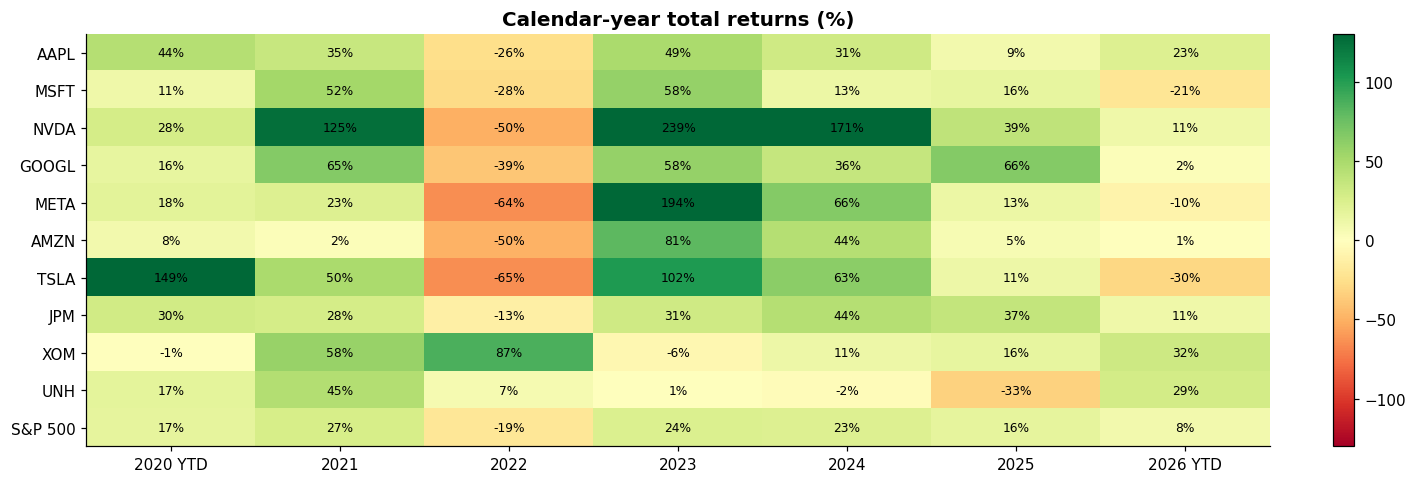

In [10]:
all_px = prices.join(benchmark)
yearly = all_px.groupby(all_px.index.year).agg(lambda s: s.dropna().iloc[-1] / s.dropna().iloc[0] - 1)
# use previous year-end as base where available (true calendar-year return)
year_end = all_px.groupby(all_px.index.year).last()
yearly.iloc[1:] = (year_end / year_end.shift(1) - 1).iloc[1:]
labels = [f'{y} YTD' if y in (all_px.index[0].year, all_px.index[-1].year) else str(y) for y in yearly.index]

fig, ax = plt.subplots(figsize=(13, 4.5))
data = yearly.T.values * 100
lim = np.nanpercentile(np.abs(data), 95)
im = ax.imshow(data, cmap='RdYlGn', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(len(labels)), labels); ax.set_yticks(range(len(yearly.columns)), yearly.columns)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f'{data[i, j]:.0f}%', ha='center', va='center', fontsize=8)
ax.grid(False); ax.set_title('Calendar-year total returns (%)')
plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()

### 4d. Liquidity check
All ten names are mega-caps, so liquidity risk should be negligible. The chart confirms it.

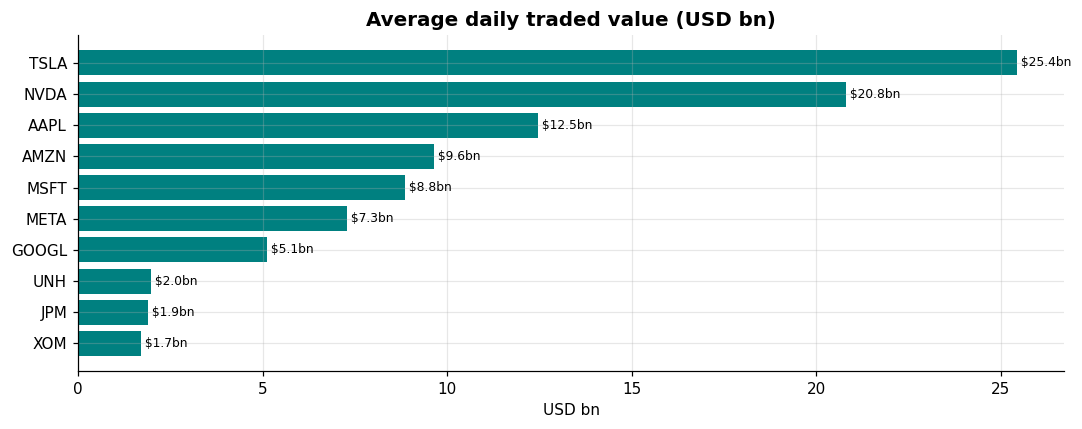

In [11]:
if volumes is not None:
    adv = quality['Avg $ vol (bn)'].sort_values()
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(adv.index, adv.values, color='teal')
    for i, v in enumerate(adv.values):
        ax.text(v, i, f' ${v:.1f}bn', va='center', fontsize=8)
    ax.set_title('Average daily traded value (USD bn)'); ax.set_xlabel('USD bn')
    plt.tight_layout(); plt.show()

## 5. Save outputs + data manifest
The manifest records exactly what was downloaded and when, so results can be reproduced and audited.

In [12]:
prices.to_csv(RAW_PRICE_FILE)
if volumes is not None:
    volumes.to_csv(RAW_VOLUME_FILE)
benchmark.to_frame('S&P 500').to_csv(BENCH_FILE)
quality.to_csv('Data_Quality_Report.csv')

manifest = {
    'project': 'QFI Market Risk Project', 'task': 'Task 1 - Data Collection', 'author': AUTHOR,
    'generated_at': datetime.now().isoformat(timespec='seconds'), 'source': DATA_SOURCE,
    'tickers': UNIVERSE, 'benchmark': BENCHMARK, 'start': START_DATE, 'end_exclusive': END_DATE,
    'first_date': str(prices.index.min().date()), 'last_date': str(prices.index.max().date()),
    'n_trading_days': int(len(prices)), 'field': 'Adj Close',
    'files': [RAW_PRICE_FILE, RAW_VOLUME_FILE, BENCH_FILE, 'Data_Quality_Report.csv'],
}
with open('data_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)
print('Saved:', ', '.join(manifest['files'] + ['data_manifest.json']))

Saved: Raw_Portfolio_Price.csv, Raw_Portfolio_Volume.csv, Benchmark_prices.csv, Data_Quality_Report.csv, data_manifest.json


## Key takeaways
- Collected **adjusted close prices and volumes** for 10 large-cap US stocks across 6 sectors, plus the S&P 500.
- Every ticker went through an automated **quality scorecard** (coverage, stale prices, bad ticks, jumps, liquidity), and the dataset is complete and aligned to the benchmark calendar.
- The largest one-day moves are real earnings or macro events, so they are kept as genuine tail risk rather than removed.
- Raw data, a quality report and a reproducibility manifest are saved for the next phase.

**Next → Task 2: Data Cleaning** (calendar alignment, outlier policy, returns, volatility models).

*Prepared by Arham Shah.*